In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 20)

In [2]:
from google.colab import files

uploaded = files.upload()

Saving MatchResults refined .xlsx to MatchResults refined .xlsx


In [3]:
file_name = "MatchResults refined .xlsx"

bat = pd.read_excel(file_name, sheet_name="Batting")
team_bat = pd.read_excel(file_name, sheet_name="TeamBat")
bowl = pd.read_excel(file_name, sheet_name="Bowling")

print("Batting shape:", bat.shape)
print("TeamBat shape:", team_bat.shape)
print("Bowling shape:", bowl.shape)

Batting shape: (745, 15)
TeamBat shape: (835, 14)
Bowling shape: (566, 16)


In [4]:
# Convert dates
bat["Date"] = pd.to_datetime(bat["Date"], errors="coerce")
team_bat["Date"] = pd.to_datetime(team_bat["Date"], errors="coerce")
bowl["Date"] = pd.to_datetime(bowl["Date"], errors="coerce")

# Convert numeric columns
bat_numeric = ["R", "B", "M", "4s", "6s", "SR", "Chase", "Win",
               "BoundaryRate", "RunMint"]

bowl_numeric = ["O", "M", "R", "W", "Econ", "Dots", "4s", "6s",
                "Wide", "NB", "Win", "Potential"]

for col in bat_numeric:
    bat[col] = pd.to_numeric(bat[col], errors="coerce").fillna(0)

for col in bowl_numeric:
    bowl[col] = pd.to_numeric(bowl[col], errors="coerce").fillna(0)

print("Data cleaned successfully!")

Data cleaned successfully!


/tmp/ipykernel_4971/1182510336.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  bat["Date"] = pd.to_datetime(bat["Date"], errors="coerce")
/tmp/ipykernel_4971/1182510336.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  team_bat["Date"] = pd.to_datetime(team_bat["Date"], errors="coerce")
/tmp/ipykernel_4971/1182510336.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  bowl["Date"] = pd.to_datetime(bowl["Date"], errors="coerce")


Question 1:  Who are the top 10 batsmen based on their total runs scored across all matches?

In [5]:
top_10_runs = (
    bat.groupby("Player")
    .agg(
        Total_Runs=("R", "sum"),
        Balls_Faced=("B", "sum"),
        Fours=("4s", "sum"),
        Sixes=("6s", "sum")
    )
    .sort_values("Total_Runs", ascending=False)
    .head(10)
    .reset_index()
)

top_10_runs

,Player,Total_Runs,Balls_Faced,Fours,Sixes
0,Sahibzada Farhan,383,235,37,18
1,Brian Bennett,277,204,31,6
2,Aiden Markram (c),236,137,26,9
3,Suryakumar Yadav (c),231,146,25,11
4,Shimron Hetmyer,221,121,15,17
5,Pathum Nissanka,207,135,22,6
6,Pavan Rathnayake,205,132,20,7
7,Ryan Rickelton,197,111,17,11
8,Finn Allen,189,109,14,12
9,Shubham Ranjane,178,100,11,11


### Question 2: Which 10 players have the highest strike rate among players who have faced at least 50 balls?

In [6]:
player_batting = (
    bat.groupby("Player")
    .agg(
        Runs=("R", "sum"),
        Balls=("B", "sum"),
        Fours=("4s", "sum"),
        Sixes=("6s", "sum")
    )
)

player_batting["Strike_Rate"] = (
    player_batting["Runs"] / player_batting["Balls"] * 100
)

top_10_strike_rate = (
    player_batting[player_batting["Balls"] >= 50]
    .sort_values("Strike_Rate", ascending=False)
    .head(10)
    .reset_index()
)

top_10_strike_rate

,Player,Runs,Balls,Fours,Sixes,Strike_Rate
0,Mitchell Marsh,118,60,15,6,196.666667
1,Fakhar Zaman,109,58,11,6,187.931034
2,KamIndiau Mendis,101,54,10,4,187.037037
3,Sherfane Rutherford,145,78,9,11,185.897436
4,LorCanada Tucker (c)†,94,51,10,4,184.313725
5,Shimron Hetmyer,221,121,15,17,182.644628
6,Ben Manenti,138,77,11,8,179.220779
7,Shubham Ranjane,178,100,11,11,178.000000
8,Ryan Rickelton,197,111,17,11,177.477477
9,Jason Holder,104,59,5,10,176.271186


### Question 3:Which player has scored the most fours and which player has scored the most sixes?

In [7]:
boundary_summary = (
    bat.groupby("Player")
    .agg(
        Fours=("4s", "sum"),
        Sixes=("6s", "sum")
    )
    .sort_values(["Fours", "Sixes"], ascending=False)
)

most_fours = boundary_summary["Fours"].idxmax()
most_sixes = boundary_summary["Sixes"].idxmax()

print("Most fours:", most_fours)
print("Number of fours:", boundary_summary.loc[most_fours, "Fours"])

print("Most sixes:", most_sixes)
print("Number of sixes:", boundary_summary.loc[most_sixes, "Sixes"])

Most fours: Sahibzada Farhan
Number of fours: 37
Most sixes: Sahibzada Farhan
Number of sixes: 18


### Question 4: Which team has won the highest number of matches, and how many matches did they win?

In [8]:
matches = bat[["Date", "Team", "Vs", "Win"]].drop_duplicates()

team_wins = (
    matches.groupby("Team")["Win"]
    .sum()
    .sort_values(ascending=False)
)

team_wins.head(10)

,Win
Team,
South Africa,6
West Indies,5
India,5
Pakistan,4
England,3
Sri Lanka,3
Afganisthan,2
Australia,2
USA,2


### Question 5: For each match, who was the highest run scorer? Can you display the player name, team, opponent, match date, and runs scored?

In [9]:
match_top_scorers = (
    bat.sort_values("R", ascending=False)
    .groupby(["Date", "Team", "Vs"], as_index=False)
    .first()
)

match_top_scorers = match_top_scorers[
    ["Date", "Team", "Vs", "Player", "R"]
]

match_top_scorers = match_top_scorers.rename(
    columns={
        "Date": "Match_Date",
        "Vs": "Opponent",
        "R": "Runs_Scored"
    }
)

match_top_scorers

,Match_Date,Team,Opponent,Player,Runs_Scored
0,2026-02-13,Australia,Zimbawe,Matt Renshaw,65
1,2026-02-13,Canada,UAE,Harsh Thaker,50
2,2026-02-13,Netherland,USA,Bas de Leede,23
3,2026-02-13,UAE,Canada,Aryansh Sharma †,74
4,2026-02-13,USA,Netherland,Saiteja Mukkamalla,79
5,2026-02-13,Zimbabwe,Australia,Brian Bennett,64
6,2026-02-14,England,Scotland,Tom Banton,63
7,2026-02-14,Ireland,Oman,LorCanada Tucker (c)†,94
8,2026-02-14,New Zealand,South Africa,Mark Chapman,48
9,2026-02-14,Oman,Ireland,Aamir Kaleem,50


In [10]:
display(match_top_scorers.to_string(index=False))

'Match_Date         Team     Opponent                Player  Runs_Scored\n2026-02-13    Australia      Zimbawe          Matt Renshaw           65\n2026-02-13       Canada          UAE          Harsh Thaker           50\n2026-02-13   Netherland          USA          Bas de Leede           23\n2026-02-13          UAE       Canada      Aryansh Sharma †           74\n2026-02-13          USA   Netherland    Saiteja Mukkamalla           79\n2026-02-13     Zimbabwe    Australia         Brian Bennett           64\n2026-02-14      England     Scotland            Tom Banton           63\n2026-02-14      Ireland         Oman LorCanada Tucker (c)†           94\n2026-02-14  New Zealand South Africa          Mark Chapman           48\n2026-02-14         Oman      Ireland          Aamir Kaleem           50\n2026-02-14     Scotland      England Richie Berrington (c)           49\n2026-02-14 South Africa  New Zealand     Aiden Markram (c)           86\n2026-02-15        India     Pakistan  Suryakumar Y

### Question 6: Do teams perform better while chasing or while batting first? Compare their average runs and overall performance in both situations

In [11]:
chasing_analysis = (
    bat.groupby("Chase")
    .agg(
        Average_Runs=("R", "mean"),
        Total_Runs=("R", "sum"),
        Innings=("R", "count"),
        Wins=("Win", "sum")
    )
)

chasing_analysis["Win_Percentage"] = (
    chasing_analysis["Wins"] /
    chasing_analysis["Innings"] * 100
)

chasing_analysis.index = [
    "Batting First" if x == 0 else "Chasing"
    for x in chasing_analysis.index
]

chasing_analysis

,Average_Runs,Total_Runs,Innings,Wins,Win_Percentage
Batting First,19.270619,7477,388,170,43.814433
Chasing,18.492997,6602,357,131,36.694678


### Question 7: Who are the top 10 bowlers based on total wickets taken, and what are their average economy rates?

In [12]:
bowler_summary = (
    bowl.groupby("Bowler")
    .agg(
        Total_Wickets=("W", "sum"),
        Total_Overs=("O", "sum"),
        Runs_Conceded=("R", "sum")
    )
)

bowler_summary["Average_Economy"] = (
    bowler_summary["Runs_Conceded"] /
    bowler_summary["Total_Overs"] * 6
)

top_10_bowlers = (
    bowler_summary
    .sort_values(
        ["Total_Wickets", "Average_Economy"],
        ascending=[False, True]
    )
    .head(10)
    .reset_index()
)

top_10_bowlers

,Bowler,Total_Wickets,Total_Overs,Runs_Conceded,Average_Economy
0,Shadley van Schalkwyk,13.0,14.5,101.0,41.793103
1,Lungi Ngidi,11.0,20.0,136.0,40.800000
2,Marco Jansen,11.0,19.5,184.0,56.615385
3,Usman Tariq,10.0,19.3,141.0,43.834197
4,Blessing Muzarabani,10.0,16.0,118.0,44.250000
5,Gudakesh Motie,10.0,20.0,155.0,46.500000
6,Corbin Bosch,9.0,19.0,116.0,36.631579
7,Rachin Ravindra,9.0,13.0,88.0,40.615385
8,Michael Leask,9.0,16.0,122.0,45.750000
9,Adil Rashid,9.0,20.0,154.0,46.200000


### Question 8: Which players have scored the most runs through boundaries (fours and sixes), and how does their strike rate compare with other players

In [13]:
boundary_players = (
    bat.groupby("Player")
    .agg(
        Runs=("R", "sum"),
        Balls=("B", "sum"),
        Fours=("4s", "sum"),
        Sixes=("6s", "sum")
    )
)

boundary_players["Boundary_Runs"] = (
    boundary_players["Fours"] * 4 +
    boundary_players["Sixes"] * 6
)

boundary_players["Strike_Rate"] = (
    boundary_players["Runs"] /
    boundary_players["Balls"] * 100
)

top_boundary_players = (
    boundary_players
    .sort_values("Boundary_Runs", ascending=False)
    .head(10)
    .reset_index()
)

top_boundary_players

,Player,Runs,Balls,Fours,Sixes,Boundary_Runs,Strike_Rate
0,Sahibzada Farhan,383,235,37,18,256,162.978723
1,Suryakumar Yadav (c),231,146,25,11,166,158.219178
2,Shimron Hetmyer,221,121,15,17,162,182.644628
3,Brian Bennett,277,204,31,6,160,135.784314
4,Aiden Markram (c),236,137,26,9,158,172.262774
5,Ryan Rickelton,197,111,17,11,134,177.477477
6,Finn Allen,189,109,14,12,128,173.394495
7,Tim Seifert †,175,102,21,7,126,171.568627
8,Pathum Nissanka,207,135,22,6,124,153.333333
9,Pavan Rathnayake,205,132,20,7,122,155.303030


### Question 9:Can you create a Player Performance Score using runs, strike rate, fours, sixes, and balls faced, and use it to rank the top 20 batsmen?

In [14]:
performance = (
    bat.groupby("Player")
    .agg(
        Runs=("R", "sum"),
        Balls=("B", "sum"),
        Fours=("4s", "sum"),
        Sixes=("6s", "sum")
    )
)

performance["Strike_Rate"] = (
    performance["Runs"] /
    performance["Balls"] * 100
)

# Normalize each component
performance["Runs_N"] = performance["Runs"] / performance["Runs"].max()
performance["SR_N"] = performance["Strike_Rate"] / performance["Strike_Rate"].max()
performance["Fours_N"] = performance["Fours"] / performance["Fours"].max()
performance["Sixes_N"] = performance["Sixes"] / performance["Sixes"].max()
performance["Balls_N"] = performance["Balls"] / performance["Balls"].max()

# Calculate Player Performance Score
performance["PPS"] = 100 * (
    0.35 * performance["Runs_N"] +
    0.25 * performance["SR_N"] +
    0.15 * performance["Fours_N"] +
    0.15 * performance["Sixes_N"] +
    0.10 * performance["Balls_N"]
)

top_20_batsmen = (
    performance
    .sort_values("PPS", ascending=False)
    .head(20)
    .reset_index()
)

top_20_batsmen[
    ["Player", "Runs", "Balls", "Fours", "Sixes",
     "Strike_Rate", "PPS"]
]

,Player,Runs,Balls,Fours,Sixes,Strike_Rate,PPS
0,Sahibzada Farhan,383,235,37,18,162.978723,89.816248
1,Brian Bennett,277,204,31,6,135.784314,63.905763
2,Shimron Hetmyer,221,121,15,17,182.644628,62.196563
3,Aiden Markram (c),236,137,26,9,172.262774,61.097160
4,Suryakumar Yadav (c),231,146,25,11,158.219178,61.007790
5,Ryan Rickelton,197,111,17,11,177.477477,54.918890
6,Finn Allen,189,109,14,12,173.394495,53.348650
7,Pathum Nissanka,207,135,22,6,153.333333,52.519443
8,Pavan Rathnayake,205,132,20,7,155.303030,52.410601
9,Shubham Ranjane,178,100,11,11,178.000000,50.329582


### Question 10:  Can you combine the batting and bowling data to identify the top 10 all-round performers? Create your own Match Impact Score using runs, wickets, strike rate, economy rate, boundaries, and match result?

In [15]:
# -----------------------------
# Batting summary
# -----------------------------

bat_summary = (
    bat.groupby("Player")
    .agg(
        Runs=("R", "sum"),
        Balls=("B", "sum"),
        Fours=("4s", "sum"),
        Sixes=("6s", "sum"),
        Batting_Wins=("Win", "sum")
    )
)

bat_summary["Strike_Rate"] = (
    bat_summary["Runs"] /
    bat_summary["Balls"] * 100
)

# -----------------------------
# Bowling summary
# -----------------------------

bowl_summary = (
    bowl.groupby("Bowler")
    .agg(
        Wickets=("W", "sum"),
        Overs=("O", "sum"),
        Runs_Conceded=("R", "sum"),
        Bowling_Wins=("Win", "sum")
    )
)

bowl_summary["Economy_Rate"] = (
    bowl_summary["Runs_Conceded"] /
    bowl_summary["Overs"] * 6
)

# Rename Bowler to Player
bowl_summary = bowl_summary.reset_index()
bowl_summary = bowl_summary.rename(columns={"Bowler": "Player"})
bowl_summary = bowl_summary.set_index("Player")

# -----------------------------
# Combine batting and bowling
# -----------------------------

all_rounders = bat_summary.join(
    bowl_summary,
    how="outer",
    lsuffix="_Bat",
    rsuffix="_Bowl"
).fillna(0)

all_rounders.head()

,Runs,Balls,Fours,Sixes,Batting_Wins,Strike_Rate,Wickets,Overs,Runs_Conceded,Bowling_Wins,Economy_Rate
Player,,,,,,,,,,,
Aamir Kaleem,61.0,42.0,7.0,2.0,0.0,145.238095,1.0,4.0,29.0,0.0,43.5
Aarif Sheikh,29.0,32.0,3.0,0.0,0.0,90.625000,0.0,0.0,0.0,0.0,0.0
Aasif Sheikh,33.0,27.0,0.0,2.0,1.0,122.222222,0.0,0.0,0.0,0.0,0.0
Aasif Sheikh †,31.0,30.0,4.0,0.0,0.0,103.333333,0.0,0.0,0.0,0.0,0.0
Abdullah Ahmadzai,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,3.0,22.0,1.0,44.0


In [16]:
# Normalize batting factors
all_rounders["Runs_N"] = (
    all_rounders["Runs"] /
    all_rounders["Runs"].max()
)

all_rounders["SR_N"] = (
    all_rounders["Strike_Rate"] /
    all_rounders["Strike_Rate"].max()
)

all_rounders["Fours_N"] = (
    all_rounders["Fours"] /
    all_rounders["Fours"].max()
)

all_rounders["Sixes_N"] = (
    all_rounders["Sixes"] /
    all_rounders["Sixes"].max()
)

# Normalize wickets
all_rounders["Wickets_N"] = (
    all_rounders["Wickets"] /
    all_rounders["Wickets"].max()
)

# Normalize economy: lower is better
all_rounders["Economy_N"] = (
    all_rounders["Economy_Rate"] /
    all_rounders["Economy_Rate"].max()
)

all_rounders["Economy_Score"] = (
    1 - all_rounders["Economy_N"]
)

# Normalize match wins
all_rounders["Wins_N"] = (
    all_rounders["Batting_Wins"] /
    all_rounders["Batting_Wins"].max()
)

In [17]:
all_rounders["Match_Impact_Score"] = 100 * (
    0.30 * all_rounders["Runs_N"] +
    0.15 * all_rounders["SR_N"] +
    0.10 * all_rounders["Fours_N"] +
    0.10 * all_rounders["Sixes_N"] +
    0.20 * all_rounders["Wickets_N"] +
    0.10 * all_rounders["Economy_Score"] +
    0.05 * all_rounders["Wins_N"]
)

top_10_all_rounders = (
    all_rounders
    .sort_values("Match_Impact_Score", ascending=False)
    .head(10)
    .reset_index()
)

top_10_all_rounders[
    ["Player", "Runs", "Strike_Rate", "Fours", "Sixes",
     "Wickets", "Economy_Rate", "Match_Impact_Score"]
]

,Player,Runs,Strike_Rate,Fours,Sixes,Wickets,Economy_Rate,Match_Impact_Score
0,Sahibzada Farhan,383.0,162.978723,37.0,18.0,0.0,0.000000,72.223082
1,Shimron Hetmyer,221.0,182.644628,15.0,17.0,0.0,0.000000,54.938304
2,Aiden Markram (c),236.0,172.262774,26.0,9.0,0.0,0.000000,54.075485
3,Suryakumar Yadav (c),231.0,158.219178,25.0,11.0,0.0,0.000000,52.925333
4,Ryan Rickelton,197.0,177.477477,17.0,11.0,0.0,0.000000,50.817105
5,Brian Bennett,277.0,135.784314,31.0,6.0,0.0,51.000000,49.065257
6,Finn Allen,189.0,173.394495,14.0,12.0,0.0,0.000000,48.045843
7,Hardik Pandya,160.0,158.415842,9.0,12.0,5.0,50.571429,47.917289
8,Pathum Nissanka,207.0,153.333333,22.0,6.0,0.0,0.000000,46.357015
9,Pavan Rathnayake,205.0,155.303030,20.0,7.0,0.0,0.000000,46.322810


In [18]:
all_rounders[
    (all_rounders["Runs"] > 0) &
    (all_rounders["Wickets"] > 0)
]

,Runs,Balls,Fours,Sixes,Batting_Wins,Strike_Rate,Wickets,Overs,Runs_Conceded,Bowling_Wins,Economy_Rate,Runs_N,SR_N,Fours_N,Sixes_N,Wickets_N,Economy_N,Economy_Score,Wins_N,Match_Impact_Score
Player,,,,,,,,,,,,,,,,,,,,
Aamir Kaleem,61.0,42.0,7.0,2.0,0.0,145.238095,1.0,4.0,29.0,0.0,43.500000,0.159269,0.528139,0.189189,0.111111,0.076923,0.362500,0.637500,0.000000,23.616610
Adam Zampa,3.0,3.0,0.0,0.0,0.0,100.000000,8.0,15.2,116.0,2.0,45.789474,0.007833,0.363636,0.000000,0.000000,0.615385,0.381579,0.618421,0.000000,24.181435
Aiden Markram,28.0,11.0,5.0,1.0,1.0,254.545455,1.0,3.0,34.0,3.0,68.000000,0.073107,0.925620,0.135135,0.055556,0.076923,0.566667,0.433333,0.166667,24.689544
Ansh Patel,2.0,5.0,0.0,0.0,0.0,40.000000,3.0,12.0,104.0,0.0,52.000000,0.005222,0.145455,0.000000,0.000000,0.230769,0.433333,0.566667,0.000000,12.620527
Arshdeep Singh,11.0,16.0,2.0,0.0,3.0,68.750000,8.0,18.0,128.0,4.0,42.666667,0.028721,0.250000,0.054054,0.000000,0.615385,0.355556,0.644444,0.500000,26.404296
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Tilak Varma,151.0,95.0,15.0,7.0,5.0,158.947368,1.0,2.0,11.0,1.0,33.000000,0.394256,0.577990,0.405405,0.388889,0.076923,0.275000,0.725000,0.833333,41.395604
Varun Chakravarthy,1.0,4.0,0.0,0.0,3.0,25.000000,8.0,17.0,130.0,4.0,45.882353,0.002611,0.090909,0.000000,0.000000,0.615385,0.382353,0.617647,0.500000,22.426128
Will Jacks,131.0,76.0,9.0,8.0,4.0,172.368421,3.0,10.0,116.0,3.0,69.600000,0.342037,0.626794,0.243243,0.444444,0.230769,0.580000,0.420000,0.666667,38.688605


### Chart 1 - Top 10 run scores

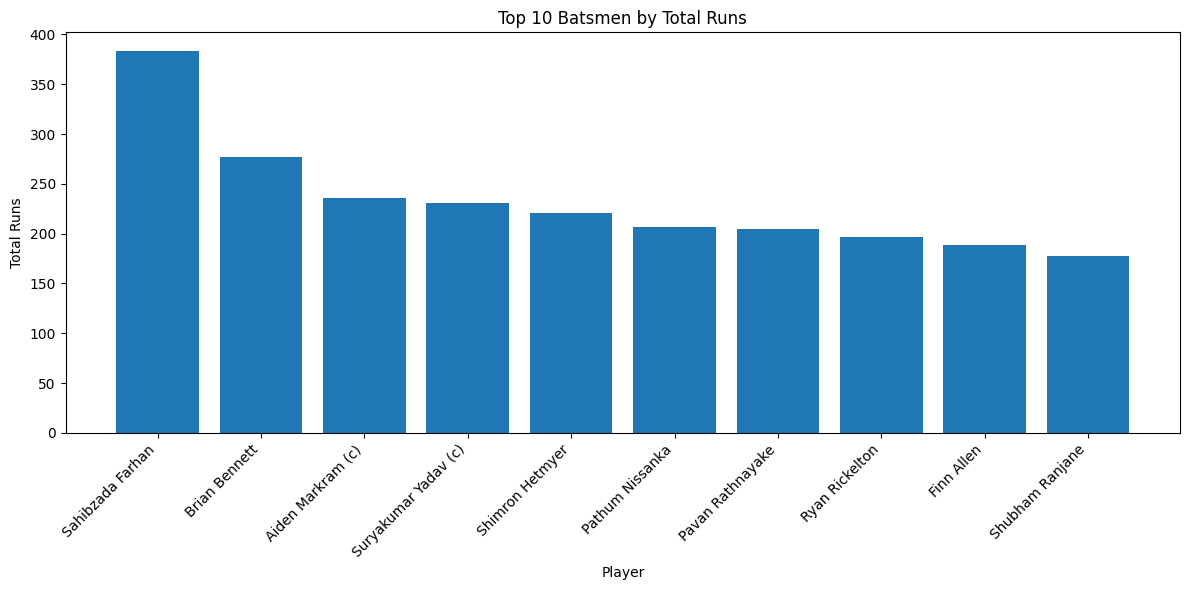

In [19]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_10_runs["Player"],
    top_10_runs["Total_Runs"]
)

plt.xticks(rotation=45, ha="right")
plt.xlabel("Player")
plt.ylabel("Total Runs")
plt.title("Top 10 Batsmen by Total Runs")
plt.tight_layout()
plt.show()

### Chart 2 - Top 10 bowlers by wickets

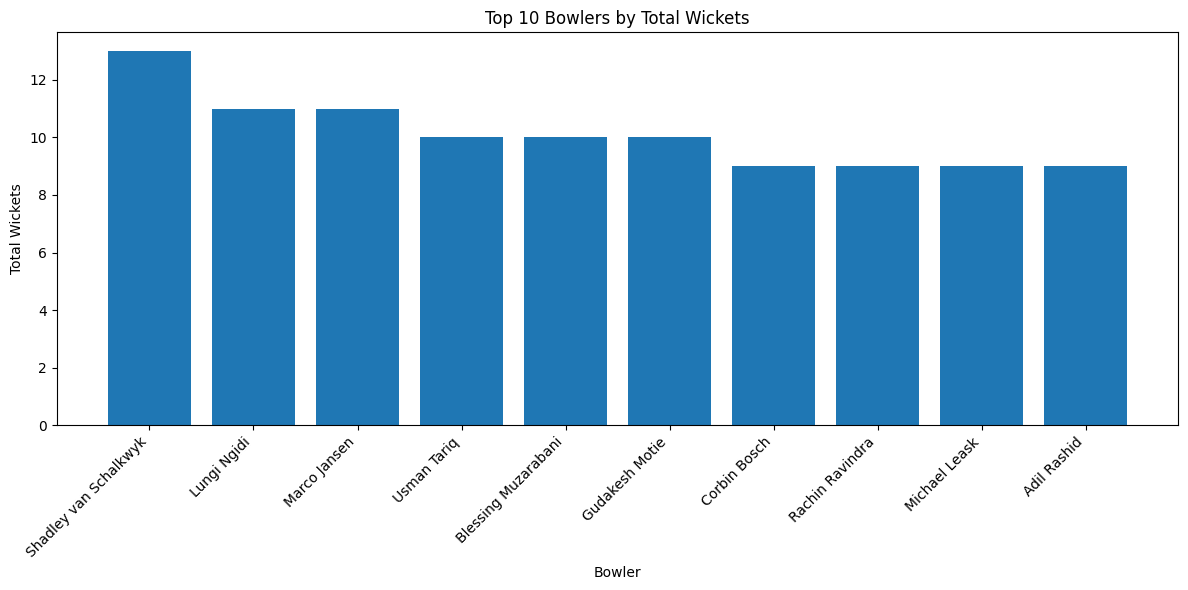

In [20]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_10_bowlers["Bowler"],
    top_10_bowlers["Total_Wickets"]
)

plt.xticks(rotation=45, ha="right")
plt.xlabel("Bowler")
plt.ylabel("Total Wickets")
plt.title("Top 10 Bowlers by Total Wickets")
plt.tight_layout()
plt.show()

### Chart 3-- Batting First vs Chasing

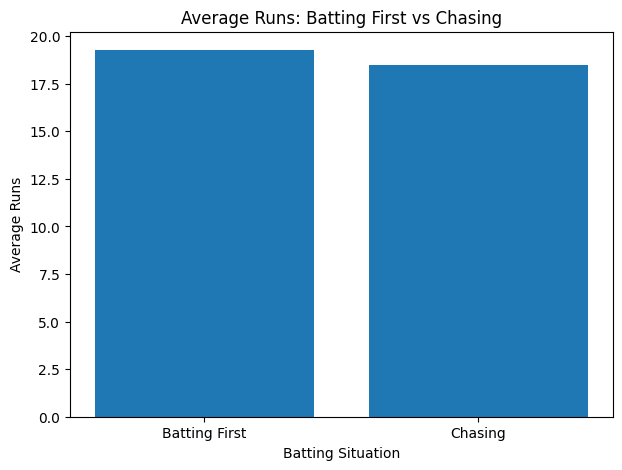

In [21]:
plt.figure(figsize=(7, 5))

plt.bar(
    chasing_analysis.index,
    chasing_analysis["Average_Runs"]
)

plt.xlabel("Batting Situation")
plt.ylabel("Average Runs")
plt.title("Average Runs: Batting First vs Chasing")
plt.show()